In [174]:
!pip install xgboost lightgbm catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [175]:
df=pd.read_csv('/content/Apartments Prices Dataset(Target column price).csv')
df

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux
...,...,...,...,...,...,...,...,...,...,...,...
5573,"13,200,000 EGP",168 m²,3 rooms,3 bathroom,5,2028,Broker,Garden,"78,571 EGP/M²",Installments,Semi Finished
5574,"2,800,000 EGP",180 m²,3 rooms,2 bathroom,3,2019,Broker,Side Street,"15,556 EGP/M²",Cash,Extra Super Lux
5575,"6,000,000 EGP",215 m²,3 rooms,2 bathroom,7,2025,Broker,Other,"27,907 EGP/M²",Cash,Semi Finished
5576,"7,500,000 EGP",400 m²,4 rooms,3 bathroom,11,2009,Broker,Main Street,"18,750 EGP/M²",Cash,Super Lux


In [176]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   price           5572 non-null   object
 1   area_sqm        5545 non-null   object
 2   rooms           5550 non-null   object
 3   bathrooms       5480 non-null   object
 4   floor_level     5578 non-null   object
 5   year_built      5578 non-null   int64 
 6   seller_type     5387 non-null   object
 7   view            5556 non-null   object
 8   price_per_sqm   5534 non-null   object
 9   payment_method  5566 non-null   object
 10  finishing_type  5578 non-null   object
dtypes: int64(1), object(10)
memory usage: 479.5+ KB


In [177]:
df.describe()

,year_built
count,5578.000000
mean,2022.327178
std,8.431095
min,1915.000000
25%,2023.000000
50%,2025.000000
75%,2026.000000
max,2037.000000


In [178]:
df.isnull().sum()

,0
price,6
area_sqm,33
rooms,28
bathrooms,98
floor_level,0
year_built,0
seller_type,191
view,22
price_per_sqm,44
payment_method,12


In [179]:
df[df.duplicated()]

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
20,"1,560,000 EGP",140 m²,3 rooms,1 bathroom,9,2014,Broker,Side Street,"11,143 EGP/M²",Cash,Extra Super Lux
55,"7,000,000 EGP",240 m²,3 rooms,3 bathroom,3,2025,Broker,Main Street,"29,167 EGP/M²",Cash,Extra Super Lux
155,"2,800,000 EGP",165 m²,3 rooms,2 bathroom,1,2026,Developer,Main Street,"16,970 EGP/M²",Cash or Installments,Semi Finished
190,"5,810,000 EGP",83 m²,2 rooms,1 bathroom,1,2025,Developer,Garden,"70,000 EGP/M²",Cash or Installments,Extra Super Lux
191,"6,000,000 EGP",225 m²,3 rooms,3 bathroom,3,2025,Broker,Garden,"26,667 EGP/M²",Cash,Semi Finished
...,...,...,...,...,...,...,...,...,...,...,...
5562,"1,000,000 EGP",140 m²,3 rooms,2 bathroom,7,2025,Broker,Side Street,"7,143 EGP/M²",Cash,Without Finish
5565,"9,500,000 EGP",122 m²,2 rooms,2 bathroom,2,2025,Broker,Garden,"77,869 EGP/M²",Cash,Extra Super Lux
5569,"13,200,000 EGP",168 m²,3 rooms,3 bathroom,5,2028,Broker,Garden,"78,571 EGP/M²",Installments,Semi Finished
5572,"19,000,000 EGP",140 m²,2 rooms,2 bathroom,2,2025,Broker,Main Street,"135,714 EGP/M²",Cash,Extra Super Lux


In [180]:
cols = ['price', 'area_sqm', 'rooms', 'bathrooms', 'price_per_sqm']

# Convert columns to string, extract numeric parts, and convert to numeric dtype
for i in cols:
    # Keep digits, dots (for floats), and remove commas/letters
    df[i] = df[i].astype(str).str.replace(',', '', regex=False)
    df[i] = df[i].str.extract(r'([\d.]+)').astype(float)

df[cols].head()

,price,area_sqm,rooms,bathrooms,price_per_sqm
0,2163000.0,120.0,2.0,3.0,18025.0
1,3250000.0,162.0,3.0,2.0,20062.0
2,2650000.0,122.0,3.0,1.0,21721.0
3,12720000.0,212.0,4.0,3.0,60000.0
4,5898000.0,135.0,2.0,1.0,43689.0


In [181]:
df.drop_duplicates()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,2163000.0,120.0,2.0,3.0,3,2025,Developer,Main Street,18025.0,Installments,Semi Finished
1,3250000.0,162.0,3.0,2.0,6,2024,Developer,Main Street,20062.0,Cash or Installments,Semi Finished
2,2650000.0,122.0,3.0,1.0,4,2024,Developer,Main Street,21721.0,Cash or Installments,Semi Finished
3,12720000.0,212.0,4.0,3.0,13,2027,Broker,Club,60000.0,Cash or Installments,Extra Super Lux
4,5898000.0,135.0,2.0,1.0,6,2025,Developer,Lake,43689.0,Cash or Installments,Super Lux
...,...,...,...,...,...,...,...,...,...,...,...
5571,5050000.0,101.0,2.0,1.0,2,2027,Broker,Pool,50000.0,Installments,Super Lux
5574,2800000.0,180.0,3.0,2.0,3,2019,Broker,Side Street,15556.0,Cash,Extra Super Lux
5575,6000000.0,215.0,3.0,2.0,7,2025,Broker,Other,27907.0,Cash,Semi Finished
5576,7500000.0,400.0,4.0,3.0,11,2009,Broker,Main Street,18750.0,Cash,Super Lux


In [182]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   price           5572 non-null   float64
 1   area_sqm        5545 non-null   float64
 2   rooms           5550 non-null   float64
 3   bathrooms       5480 non-null   float64
 4   floor_level     5578 non-null   object 
 5   year_built      5578 non-null   int64  
 6   seller_type     5387 non-null   object 
 7   view            5556 non-null   object 
 8   price_per_sqm   5498 non-null   float64
 9   payment_method  5566 non-null   object 
 10  finishing_type  5578 non-null   object 
dtypes: float64(5), int64(1), object(5)
memory usage: 479.5+ KB


In [183]:
# To select and view only the columns with 'object' (string) data types, call it directly:
df.select_dtypes(include='object')

,floor_level,seller_type,view,payment_method,finishing_type
0,3,Developer,Main Street,Installments,Semi Finished
1,6,Developer,Main Street,Cash or Installments,Semi Finished
2,4,Developer,Main Street,Cash or Installments,Semi Finished
3,13,Broker,Club,Cash or Installments,Extra Super Lux
4,6,Developer,Lake,Cash or Installments,Super Lux
...,...,...,...,...,...
5573,5,Broker,Garden,Installments,Semi Finished
5574,3,Broker,Side Street,Cash,Extra Super Lux
5575,7,Broker,Other,Cash,Semi Finished
5576,11,Broker,Main Street,Cash,Super Lux


In [184]:
df['floor_level'] = df['floor_level'].replace('Ground', '0').astype('int64')
df['floor_level']

,floor_level
0,3
1,6
2,4
3,13
4,6
...,...
5573,5
5574,3
5575,7
5576,11


In [185]:
for col in df.columns:
    print(f"Unique values in '{col}':")
    print(df[col].unique())
    print('*' * 50)

Unique values in 'price':
[2163000. 3250000. 2650000. ... 4563000. 5022000. 5050000.]
**************************************************
Unique values in 'area_sqm':
[120. 162. 122. 212. 135. 140. 145. 133. 125. 185. 154. 228. 160. 157.
 127. 130. 151. 115. 260. 134. 317. 163. 178. 176. 190. 200. 144. 250.
 167. 220. 240.  89. 128. 243.  78. 110.  47.  85. 104. 175. 235. 197.
 345. 150. 230.  62. 164. 119. 237. 100.  51. 108.  nan 152. 161. 138.
  80.  87. 123. 196. 180. 173.  90.  93.  95. 142. 107. 210. 132. 170.
 205. 136. 168. 245.  37.  52.  69. 165. 126. 252. 155. 188. 183. 225.
 143. 171. 350. 101. 255. 118. 177. 158. 198.  83.  79.  66. 181. 208.
 280. 186. 330. 114. 166. 139. 242. 147.  64. 172. 105.  76. 216.  81.
  60. 275. 211. 191.  63. 187.  75.  59.  86.  58.  57.  61.  73.  92.
  55.  56.  42. 102. 106.  68. 137.  91.  98. 229. 182.  67. 215.  40.
  94.  99. 222. 213. 159. 116.  88.  70. 450.  84.  71. 320. 195.  38.
  53.  72.  77. 121. 131.  54. 169.  50. 141.  41. 14

In [186]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   price           5572 non-null   float64
 1   area_sqm        5545 non-null   float64
 2   rooms           5550 non-null   float64
 3   bathrooms       5480 non-null   float64
 4   floor_level     5578 non-null   int64  
 5   year_built      5578 non-null   int64  
 6   seller_type     5387 non-null   object 
 7   view            5556 non-null   object 
 8   price_per_sqm   5498 non-null   float64
 9   payment_method  5566 non-null   object 
 10  finishing_type  5578 non-null   object 
dtypes: float64(5), int64(2), object(4)
memory usage: 479.5+ KB


In [187]:
df.describe()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,price_per_sqm
count,5.572000e+03,5545.000000,5550.000000,5480.000000,5578.000000,5578.000000,5498.000000
mean,6.051594e+06,144.989360,2.592072,1.992336,2.877913,2022.327178,43706.571662
std,4.530451e+06,56.518019,3.578899,0.957547,2.849707,8.431095,27288.501840
min,5.000000e+05,15.000000,1.000000,1.000000,0.000000,1915.000000,4167.000000
25%,3.400000e+06,102.000000,2.000000,1.000000,1.000000,2023.000000,25915.500000
50%,4.900000e+06,143.000000,3.000000,2.000000,2.000000,2025.000000,40433.500000
75%,7.500000e+06,179.000000,3.000000,3.000000,4.000000,2026.000000,54000.000000
max,9.838000e+07,534.000000,230.000000,23.000000,64.000000,2037.000000,655172.000000


In [188]:
ncolm = ['rooms','bathrooms','area_sqm','price_per_sqm']
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')
df[ncolm] = imputer.fit_transform(df[ncolm])


In [189]:
obcols = ['seller_type','view','payment_method']

impute = SimpleImputer(strategy='most_frequent')
df[obcols] = impute.fit_transform(df[obcols])

In [190]:
df.dropna(subset=['price'], inplace=True)

In [191]:
df.isnull().sum()

,0
price,0
area_sqm,0
rooms,0
bathrooms,0
floor_level,0
year_built,0
seller_type,0
view,0
price_per_sqm,0
payment_method,0


In [192]:
for i in df.select_dtypes('object').columns:
    print(f"Unique values in '{i}':", df[i].nunique())
    print('*' * 50)

Unique values in 'seller_type': 7
**************************************************
Unique values in 'view': 13
**************************************************
Unique values in 'payment_method': 3
**************************************************
Unique values in 'finishing_type': 5
**************************************************


In [193]:
ocols=df.select_dtypes(include='object').columns

from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')
for i in ocols:
  ohe_encoded = ohe.fit_transform(df[[i]]).toarray()
  ohe_df = pd.DataFrame(ohe_encoded, columns=ohe.get_feature_names_out([i]),index=df.index)
  df = pd.concat([df, ohe_df],axis=1)
  df.drop(i,axis=1,inplace=True)

In [194]:
df

,price,area_sqm,rooms,bathrooms,floor_level,year_built,price_per_sqm,seller_type_Broker,seller_type_Cash,seller_type_Cash or Installments,...,view_Sea View,view_Side Street,payment_method_Cash,payment_method_Cash or Installments,payment_method_Installments,finishing_type_Extra Super Lux,finishing_type_Lux,finishing_type_Semi Finished,finishing_type_Super Lux,finishing_type_Without Finish
0,2163000.0,120.0,2.0,3.0,3,2025,18025.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,3250000.0,162.0,3.0,2.0,6,2024,20062.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2,2650000.0,122.0,3.0,1.0,4,2024,21721.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,12720000.0,212.0,4.0,3.0,13,2027,60000.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
4,5898000.0,135.0,2.0,1.0,6,2025,43689.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5573,13200000.0,168.0,3.0,3.0,5,2028,78571.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
5574,2800000.0,180.0,3.0,2.0,3,2019,15556.0,1.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
5575,6000000.0,215.0,3.0,2.0,7,2025,27907.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
5576,7500000.0,400.0,4.0,3.0,11,2009,18750.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [195]:
X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [196]:
numcols = ['area_sqm', 'rooms', 'bathrooms', 'price_per_sqm','floor_level','year_built']
scaler = MinMaxScaler()
X_train[numcols] = scaler.fit_transform(X_train[numcols])
X_test[numcols] = scaler.transform(X_test[numcols])

In [197]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [198]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


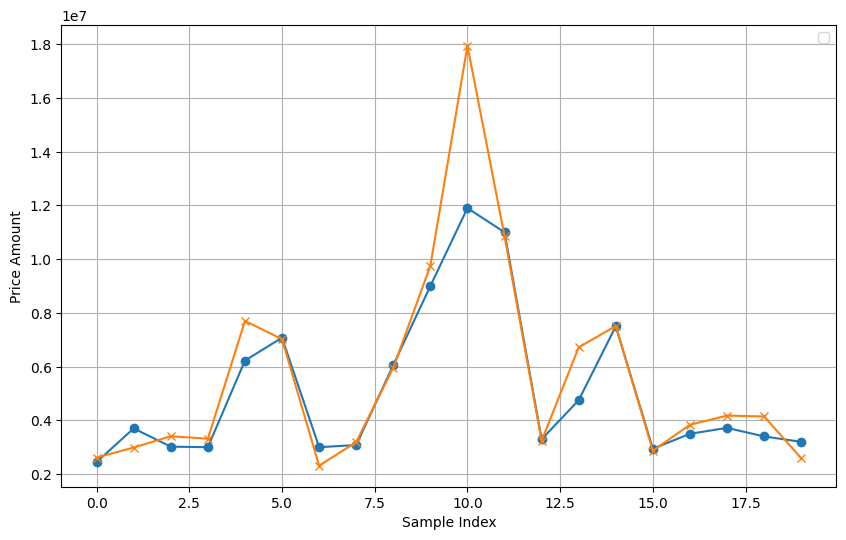

  7%|▋         | 1/15 [00:00<00:02,  5.51it/s]/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.369e+15, tolerance: 8.142e+12
  model = cd_fast.enet_coordinate_descent(
/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


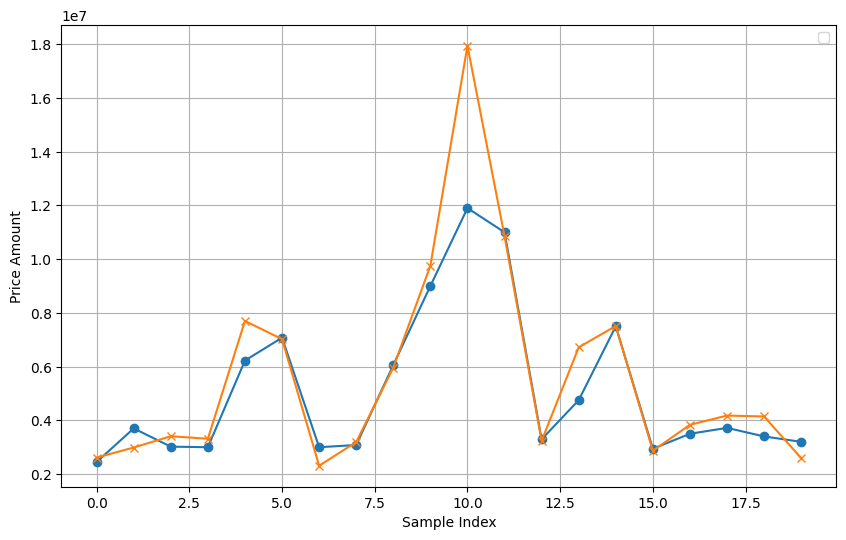

 13%|█▎        | 2/15 [00:00<00:03,  3.34it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


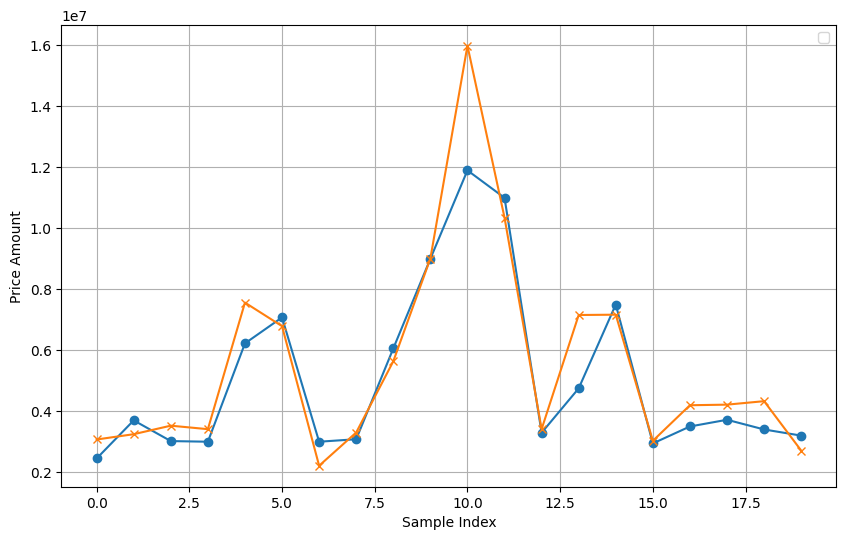

 20%|██        | 3/15 [00:00<00:03,  3.61it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


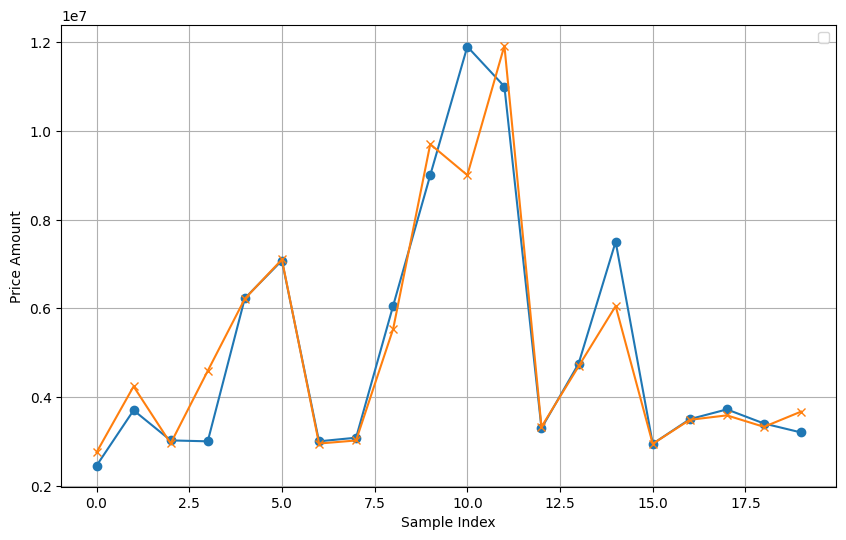

 27%|██▋       | 4/15 [00:01<00:06,  1.75it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


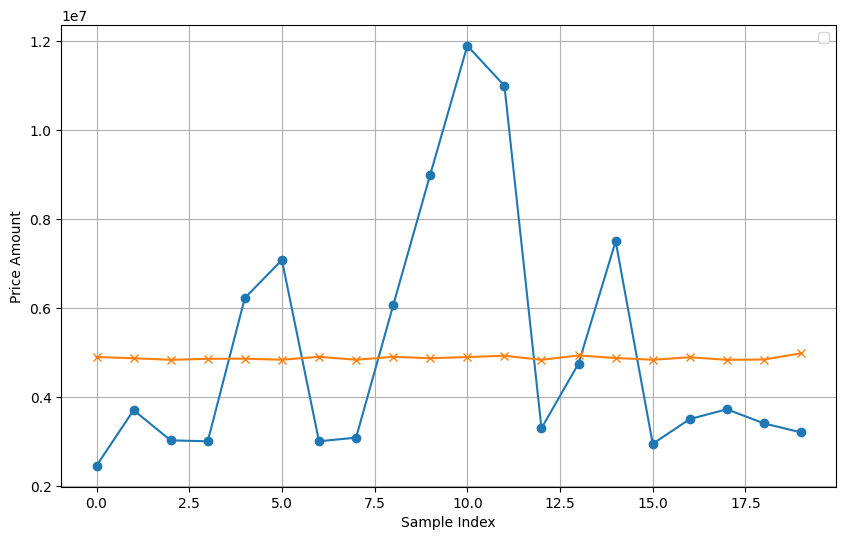

 33%|███▎      | 5/15 [00:02<00:07,  1.37it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


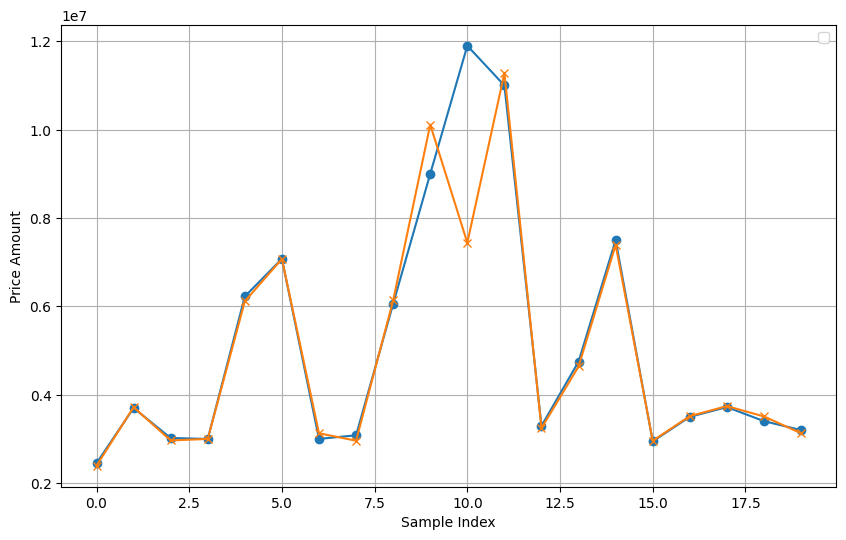

 40%|████      | 6/15 [00:03<00:04,  1.87it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


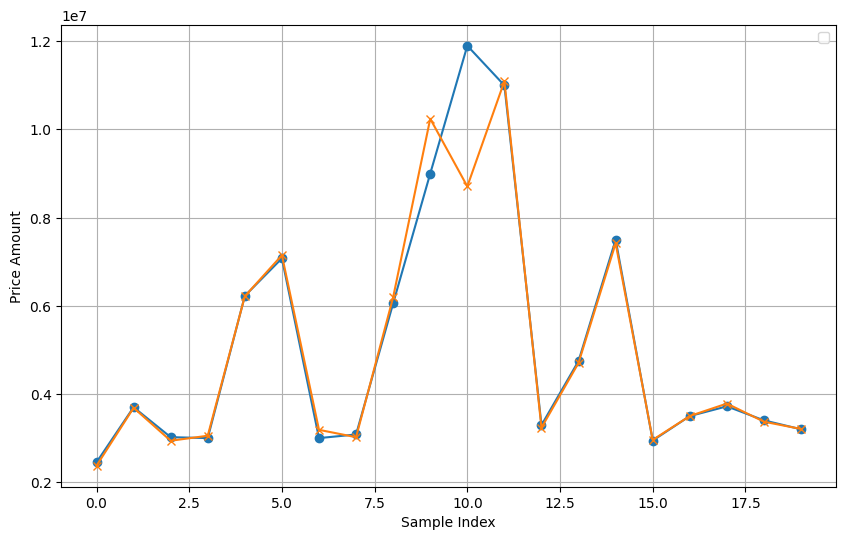

 47%|████▋     | 7/15 [00:03<00:04,  1.66it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


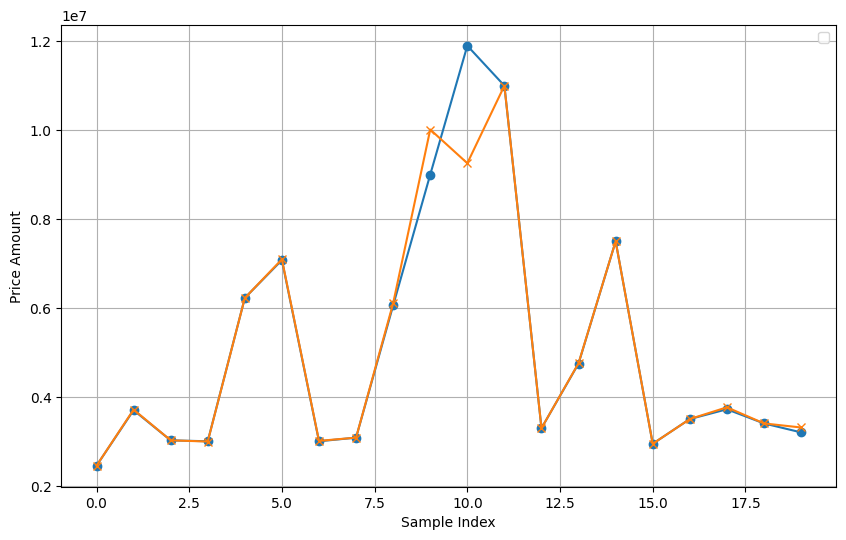

 53%|█████▎    | 8/15 [00:05<00:06,  1.04it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


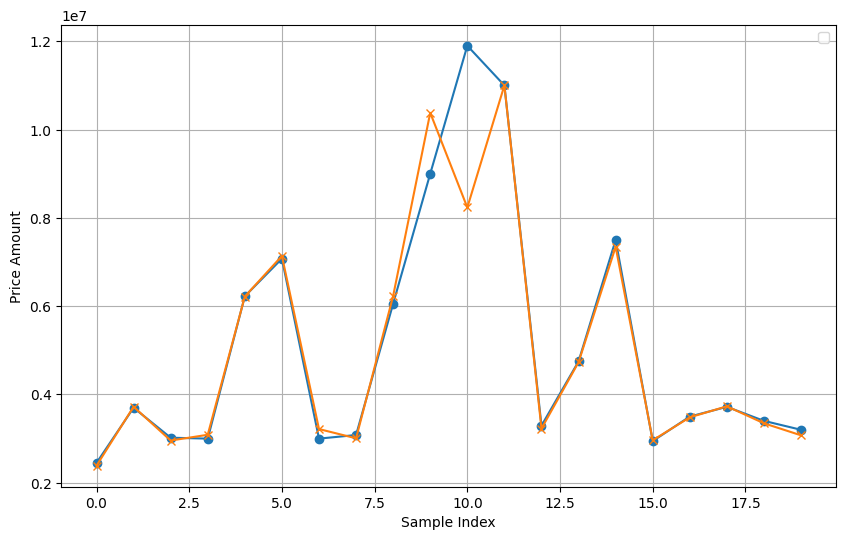

 60%|██████    | 9/15 [00:06<00:05,  1.09it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


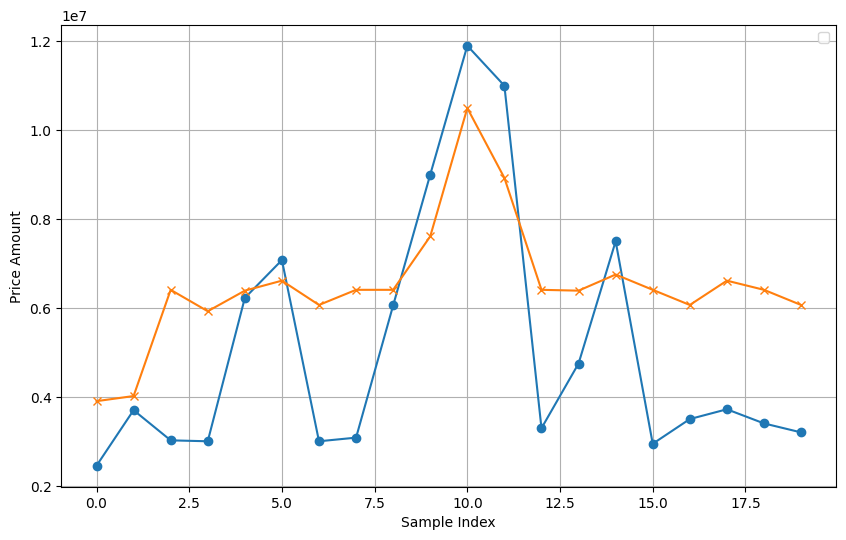

 67%|██████▋   | 10/15 [00:06<00:03,  1.41it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


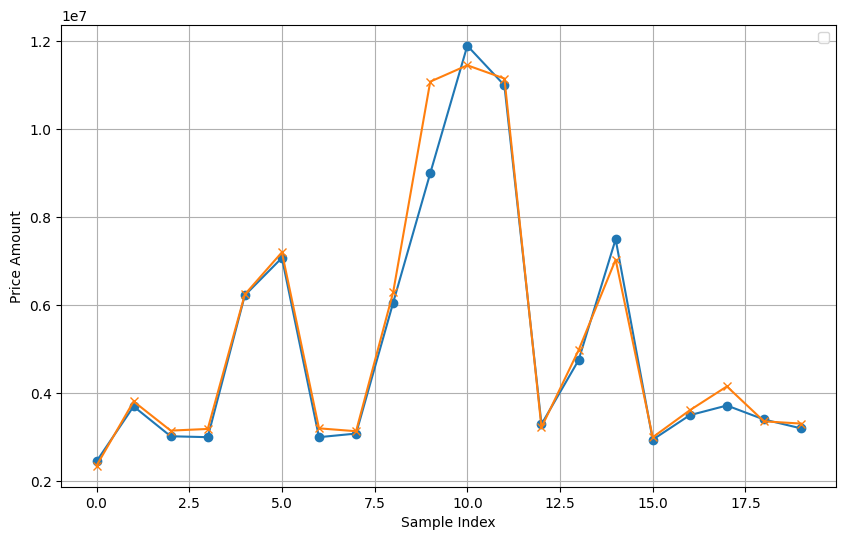

 73%|███████▎  | 11/15 [00:07<00:02,  1.41it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


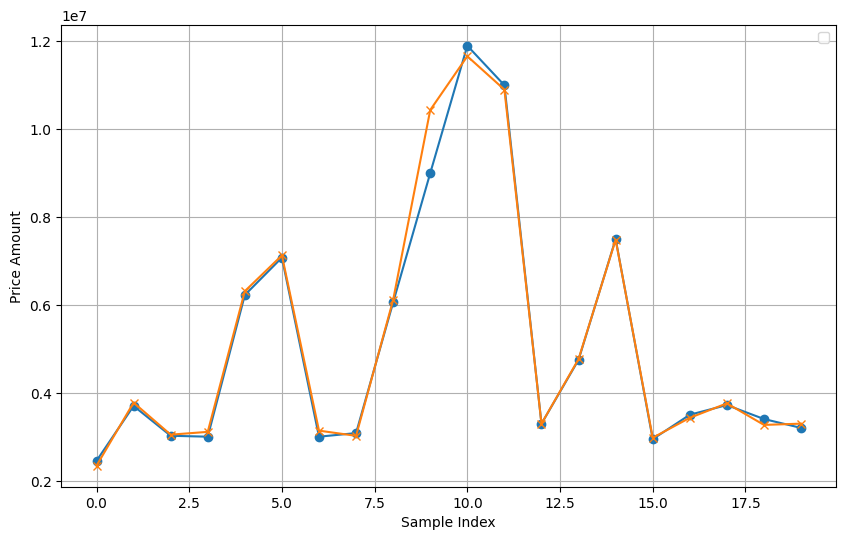

 80%|████████  | 12/15 [00:07<00:01,  1.53it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


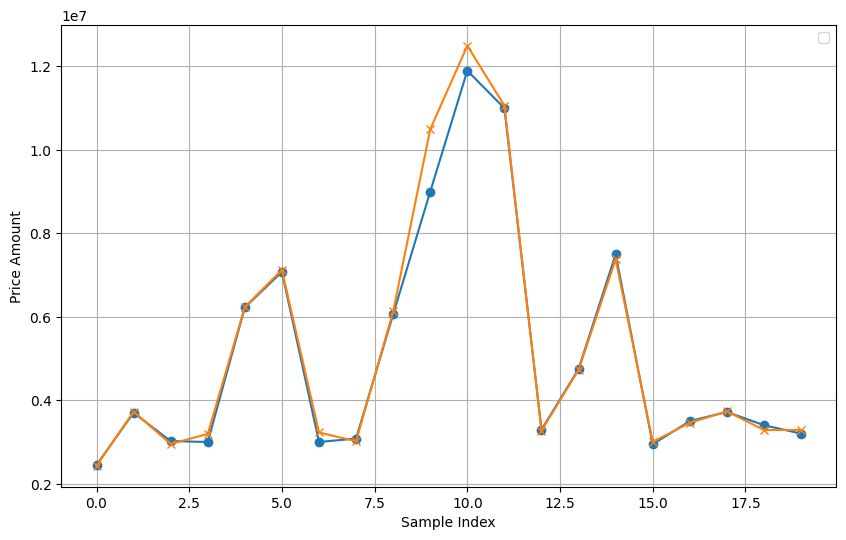

 87%|████████▋ | 13/15 [00:08<00:01,  1.81it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


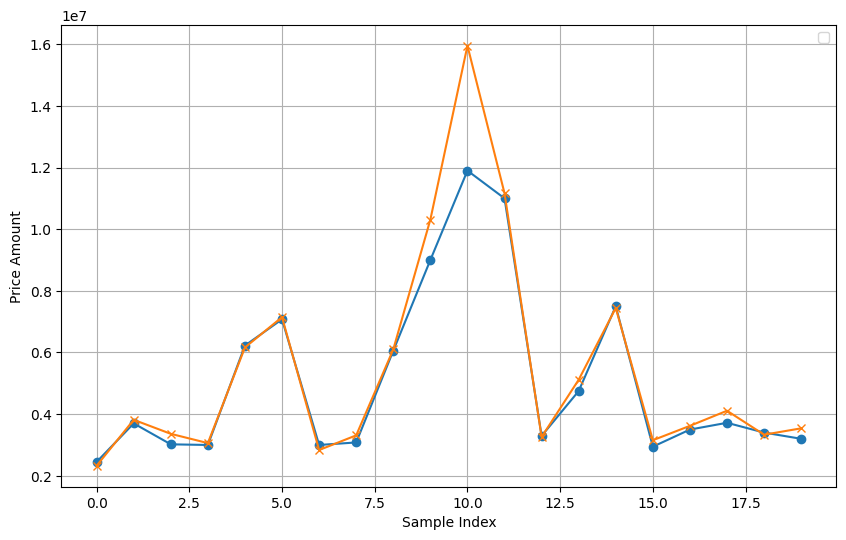

 93%|█████████▎| 14/15 [00:08<00:00,  2.04it/s]/tmp/ipykernel_1440/143205650.py:27: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001638 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 585
[LightGBM] [Info] Number of data points in the train set: 4457, number of used features: 28
[LightGBM] [Info] Start training from score 5973989.038815


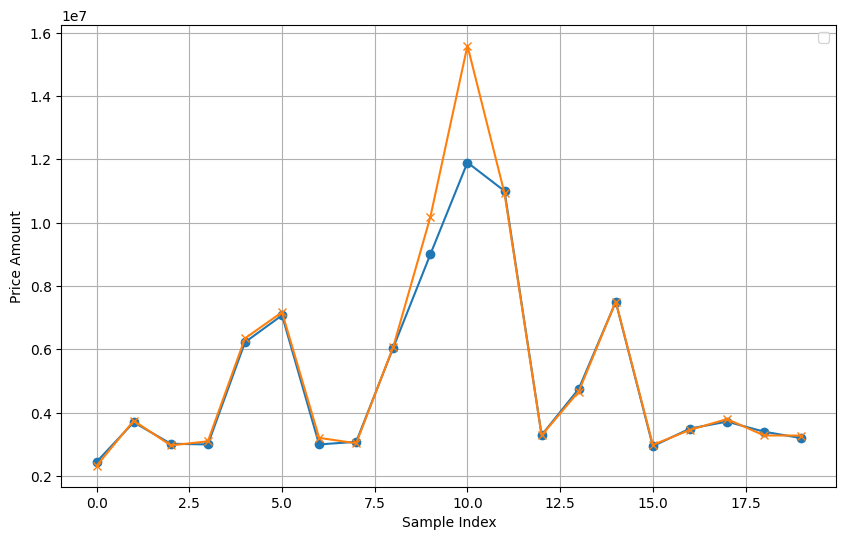

100%|██████████| 15/15 [00:08<00:00,  1.73it/s]


In [199]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, marker='o')
    plt.plot(range(20), y_pred_plot, marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Price Amount')
    plt.legend()
    plt.grid()
    plt.show()

# **Votting Regression**

In [200]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


# **Stacking Regression**

In [201]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [202]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [203]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
ExtraTrees,1.003994e+02,1.325465e+05,1.110187e+07,2.929673e+11,3.331947e+03,5.412645e+05,0.999999,0.990039
Decision Tree,1.271068e+05,2.669772e+05,6.819410e+10,5.355566e+11,2.611400e+05,7.318173e+05,0.996267,0.981791
GradientBoosting,2.093542e+05,2.793587e+05,1.767735e+11,5.393807e+11,4.204444e+05,7.344254e+05,0.990323,0.981661
Voting,2.437757e+05,3.447044e+05,2.215185e+11,5.817500e+12,4.706575e+05,2.411949e+06,0.987873,0.980878
Simple Voting,2.437757e+05,3.447044e+05,2.215185e+11,5.817500e+12,4.706575e+05,2.411949e+06,0.987873,0.980878
Weighted Voting,2.875097e+05,3.447044e+05,2.792938e+11,5.817500e+12,5.284825e+05,2.411949e+06,0.984711,0.979888
Bagging,9.936274e+04,1.944166e+05,9.867367e+10,6.926903e+11,3.141236e+05,8.322802e+05,0.994598,0.976448
Stacking,9.251522e+04,3.447044e+05,1.728769e+11,5.817500e+12,4.157847e+05,2.411949e+06,0.990536,0.975848
Random Forest,9.720660e+04,1.952593e+05,1.197033e+11,9.353512e+11,3.459816e+05,9.671356e+05,0.993447,0.968198
Linear Regression,7.075532e+05,7.628810e+05,1.560997e+12,1.730130e+12,1.249399e+06,1.315344e+06,0.914546,0.941175


<Axes: >

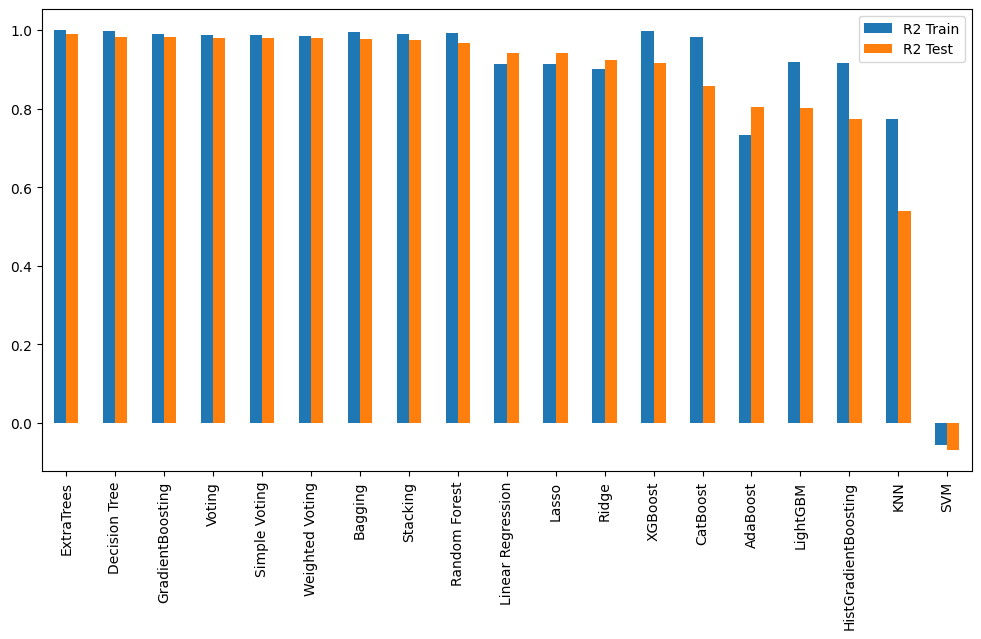

In [204]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

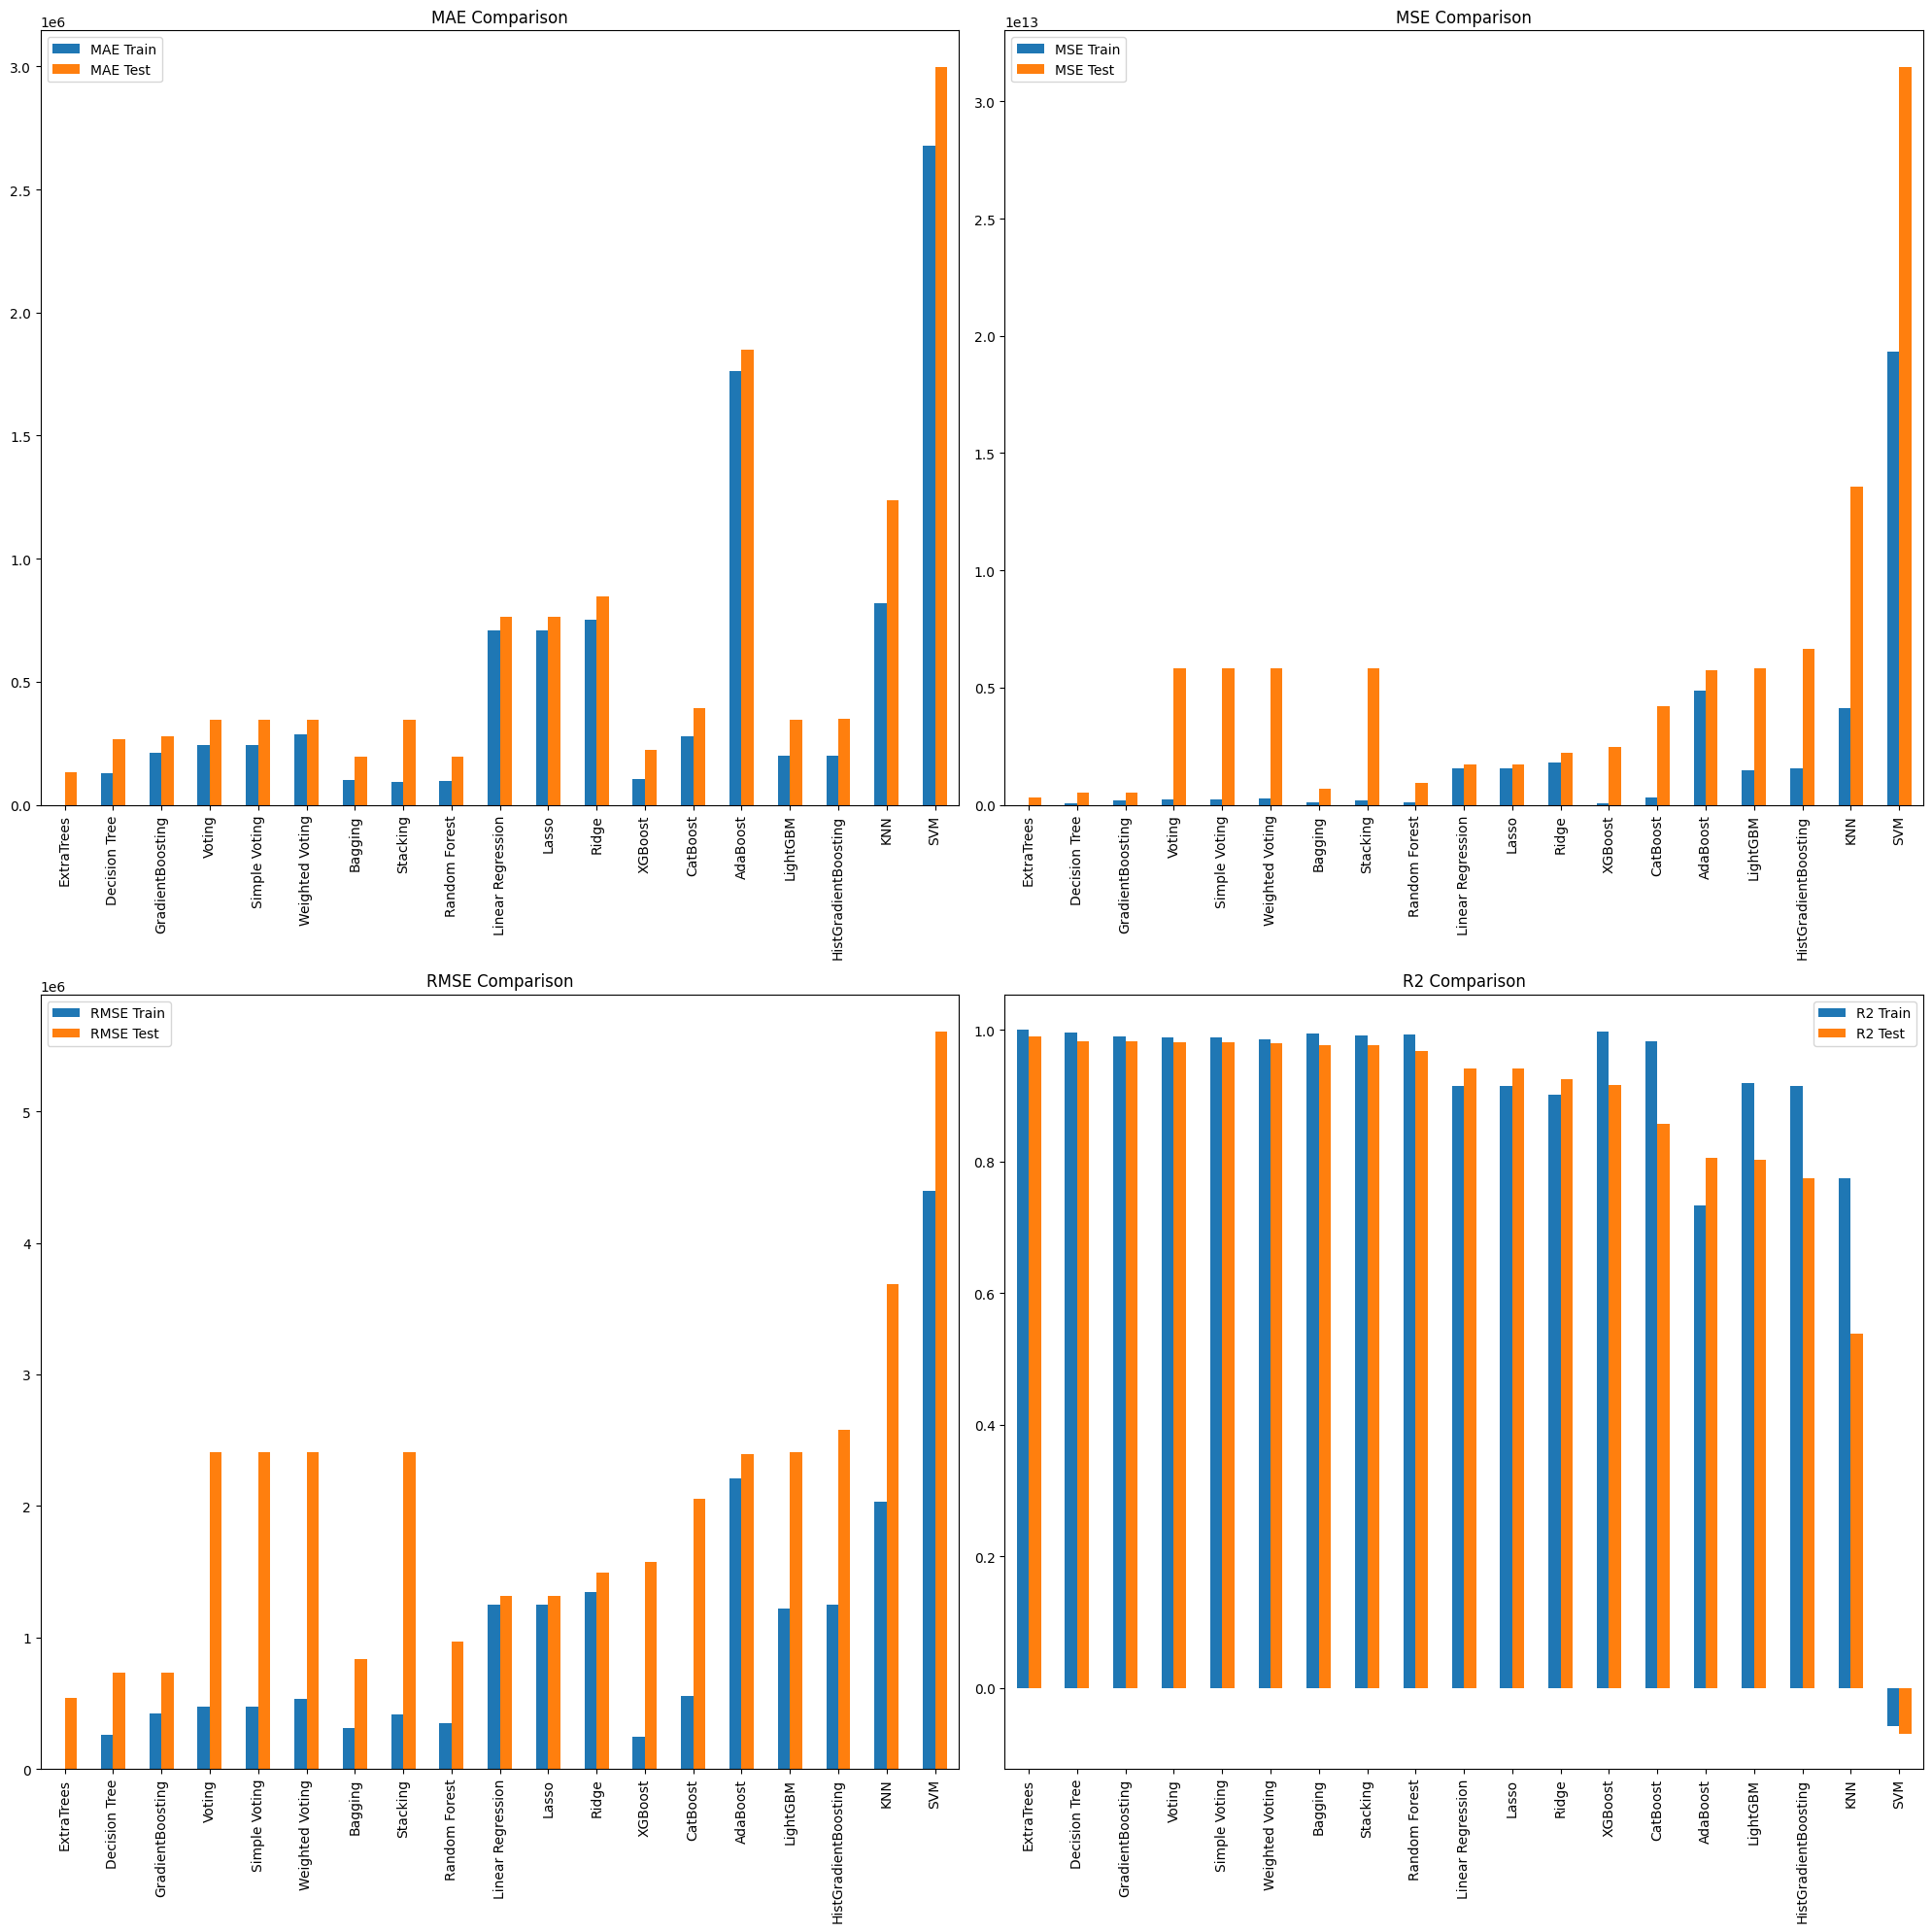

In [205]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()